---
title: "Question: Does the reason for taking the test affect the score?"
authors:
- name: "Ivan Chan"
- affiliation: "UC Berkeley"
exports:
- format: pdf
template: arxiv_two_column
output: exports/paper.pdf
---

In [2]:
import pandas as pd


demo_by_first_language = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-08-18/demo_by_first_language.csv')
demo_by_nationality = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-08-18/demo_by_nationality.csv')
demo_by_reasons = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-08-18/demo_by_reasons.csv')
performance_by_first_language = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-08-18/performance_by_first_language.csv')
performance_by_nationality = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-08-18/performance_by_nationality.csv')

In [12]:
display(demo_by_reasons.value_counts("year"))
display(demo_by_reasons.value_counts("type"))
display(demo_by_reasons.value_counts("reason"))

year
2024-2025    264
2023-2024    264
2022-2023    264
Name: count, dtype: int64

type
Academic            396
General_Training    396
Name: count, dtype: int64

reason
For employment                                                 72
For higher education extended course (three months or more)    72
For higher education short course (three months or less)       72
For immigration                                                72
For other education purposes                                   72
For personal reasons                                           72
For professional registration (NOT medical)                    72
For registration as a dentist                                  72
For registration as a doctor                                   72
For registration as a nurse (including CGFNS)                  72
(Other)                                                        72
Name: count, dtype: int64

In [8]:
demo_by_reasons

,type,reason,band,percent,year
0,Academic,For employment,<4,0.004237,2024-2025
1,Academic,For employment,4,0.009076,2024-2025
2,Academic,For employment,4.5,0.024999,2024-2025
3,Academic,For employment,5,0.063100,2024-2025
4,Academic,For employment,5.5,0.125610,2024-2025
...,...,...,...,...,...
787,General_Training,(Other),7,0.130000,2022-2023
788,General_Training,(Other),7.5,0.090000,2022-2023
789,General_Training,(Other),8,0.050000,2022-2023
790,General_Training,(Other),8.5,0.010000,2022-2023


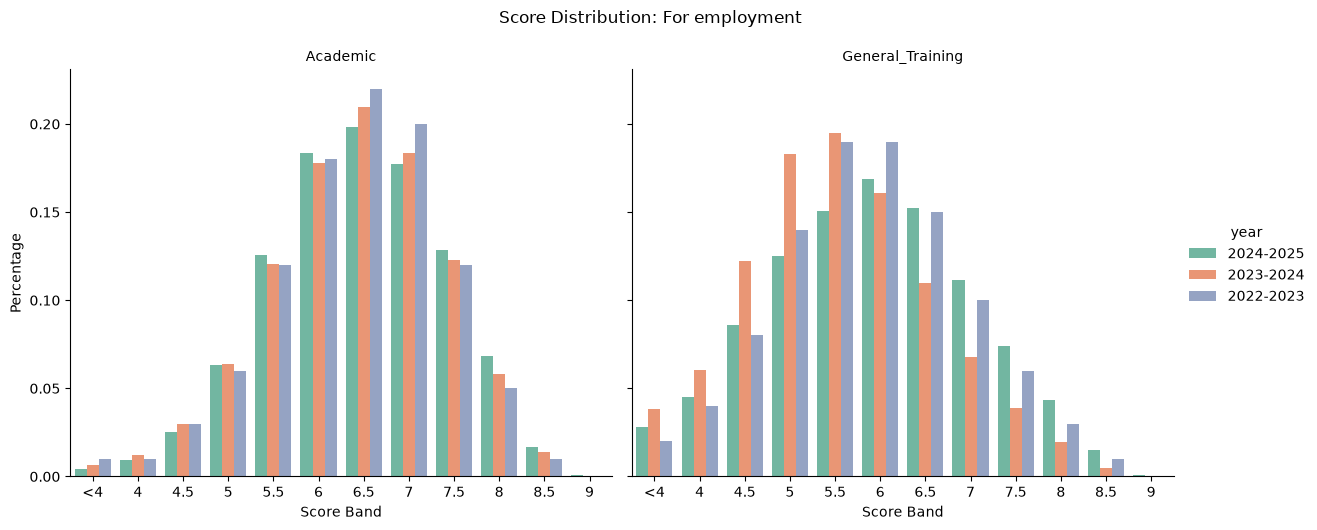

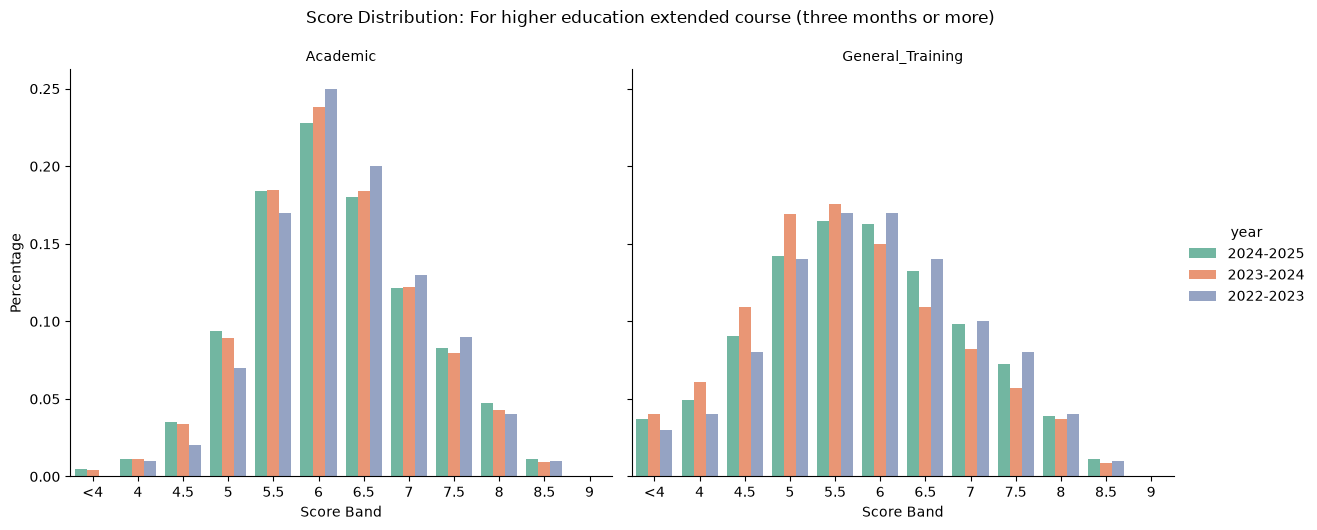

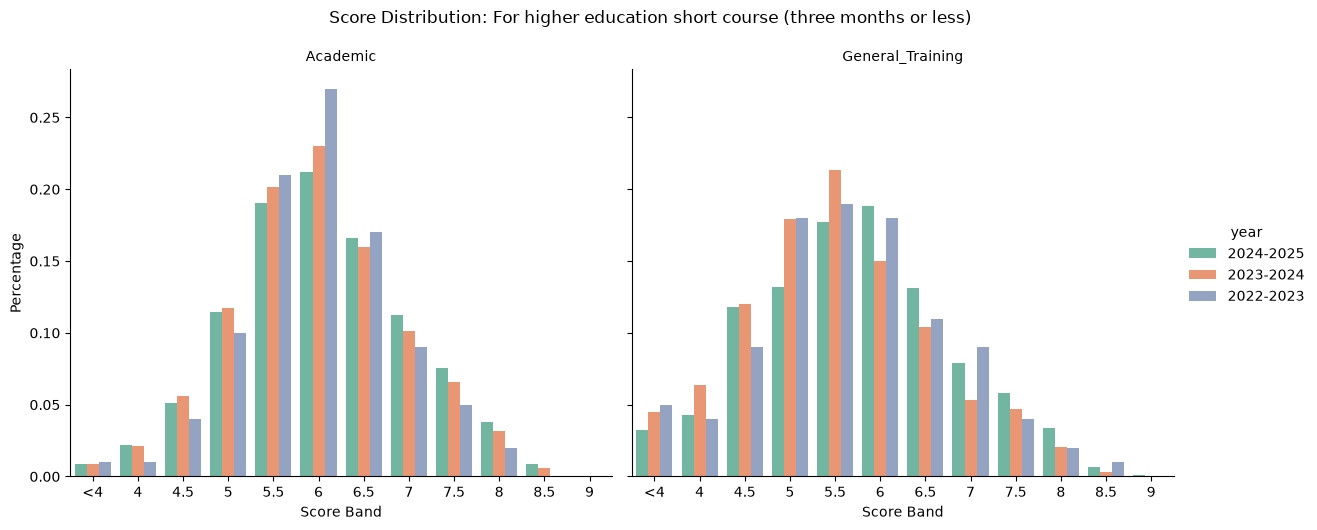

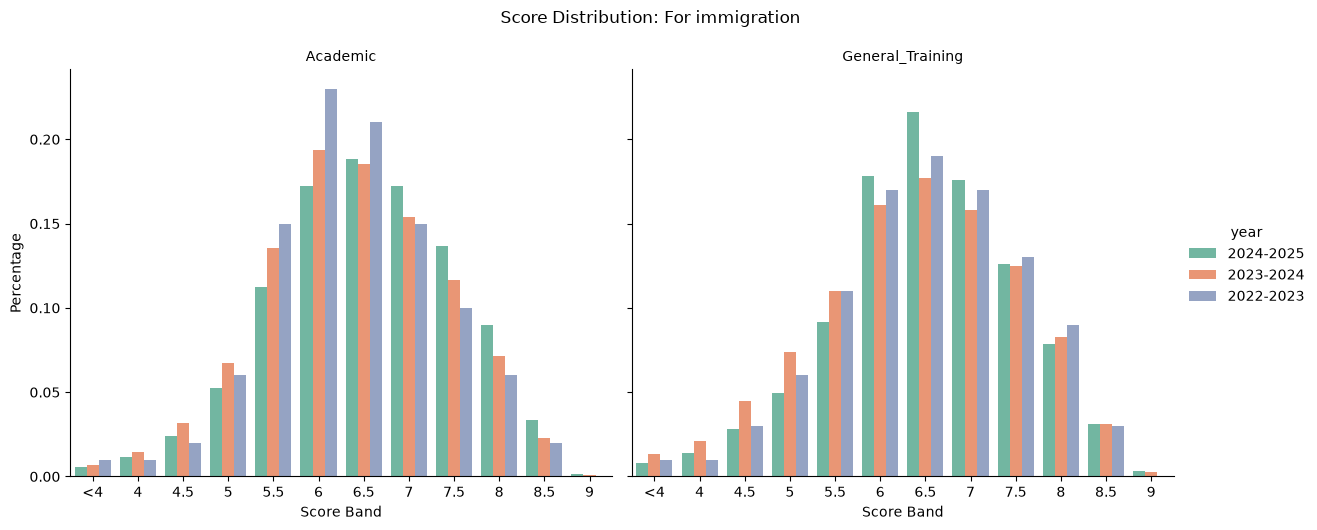

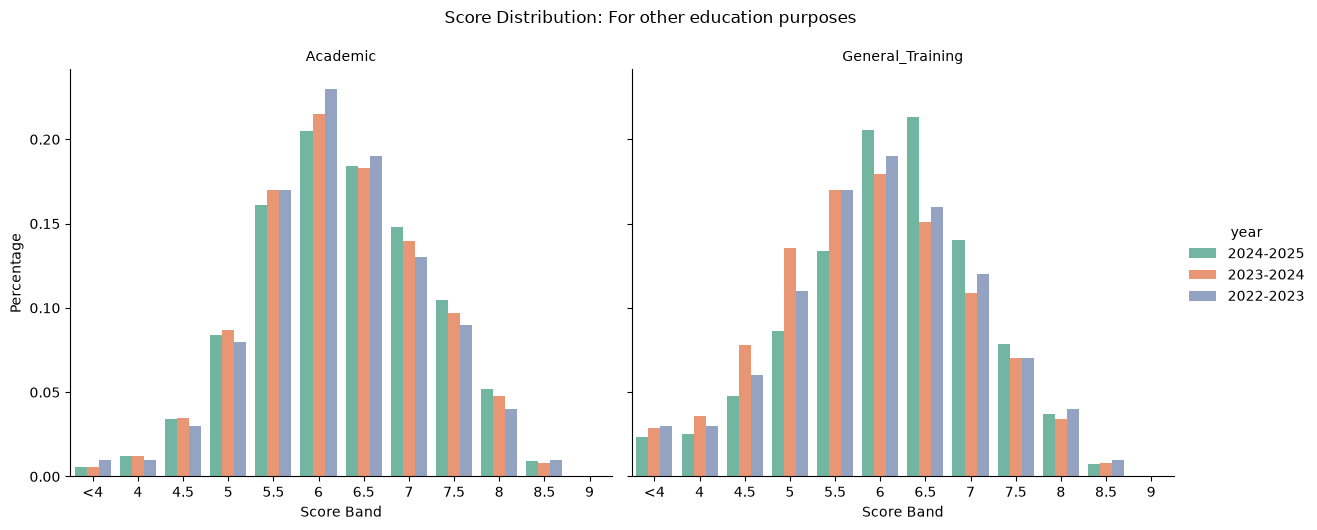

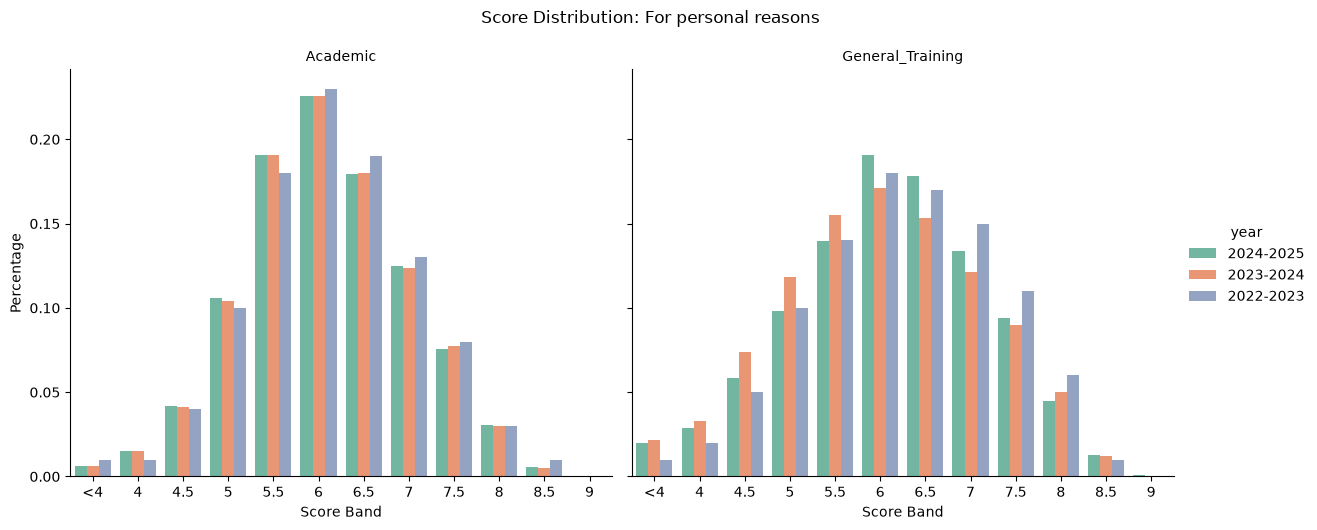

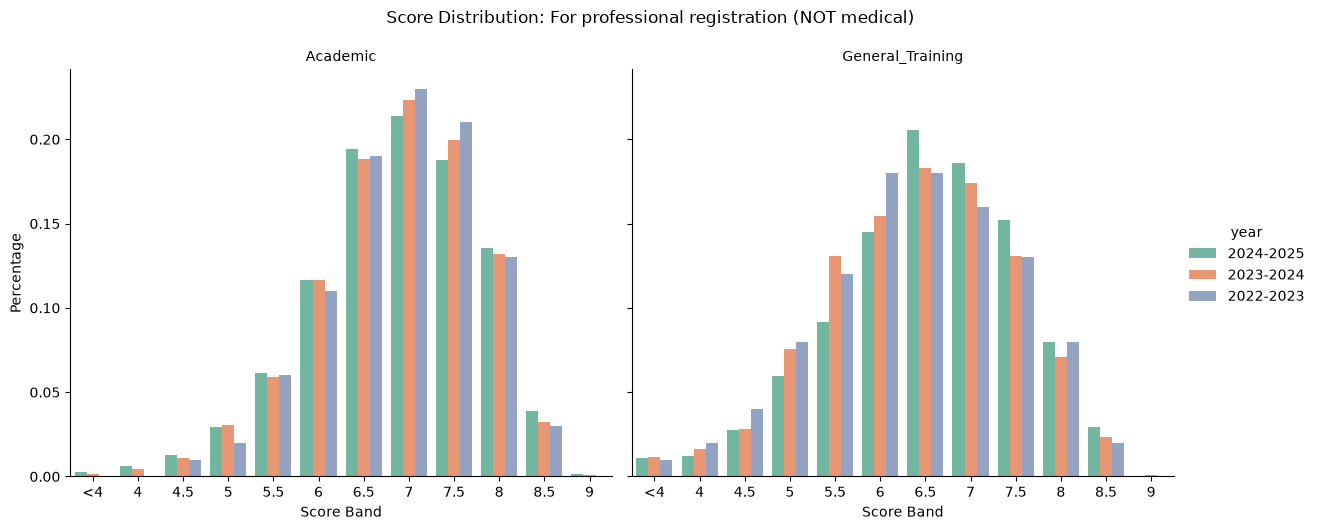

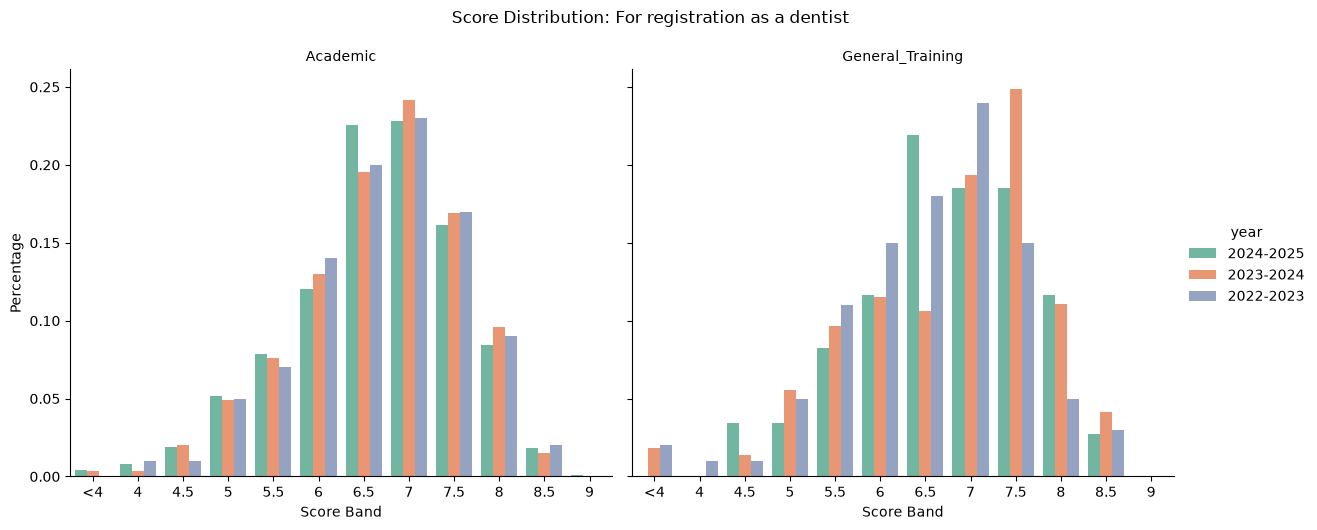

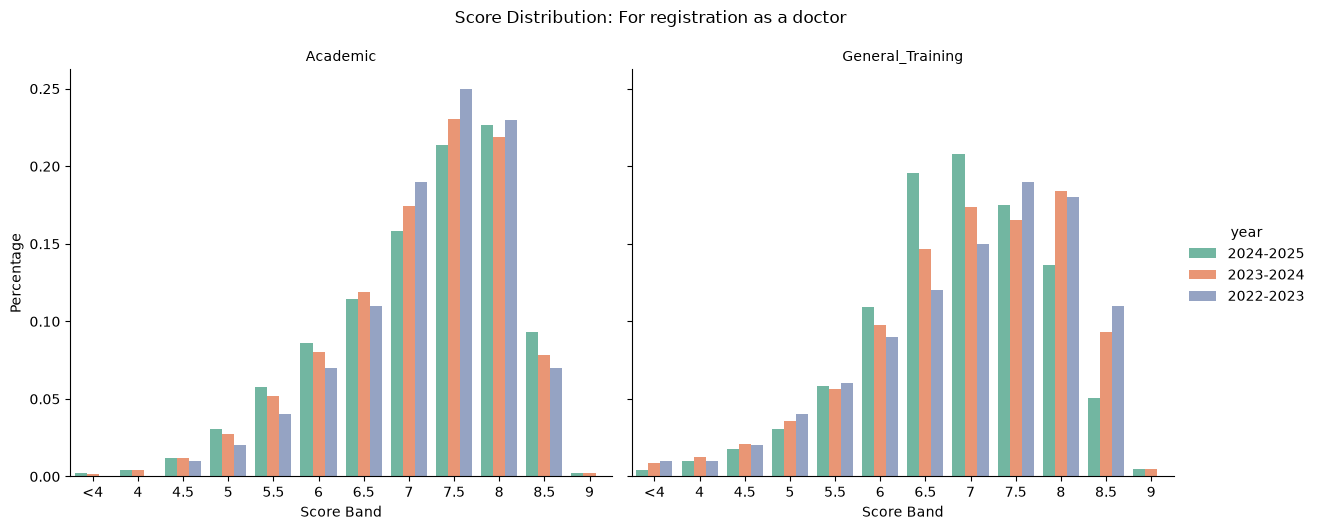

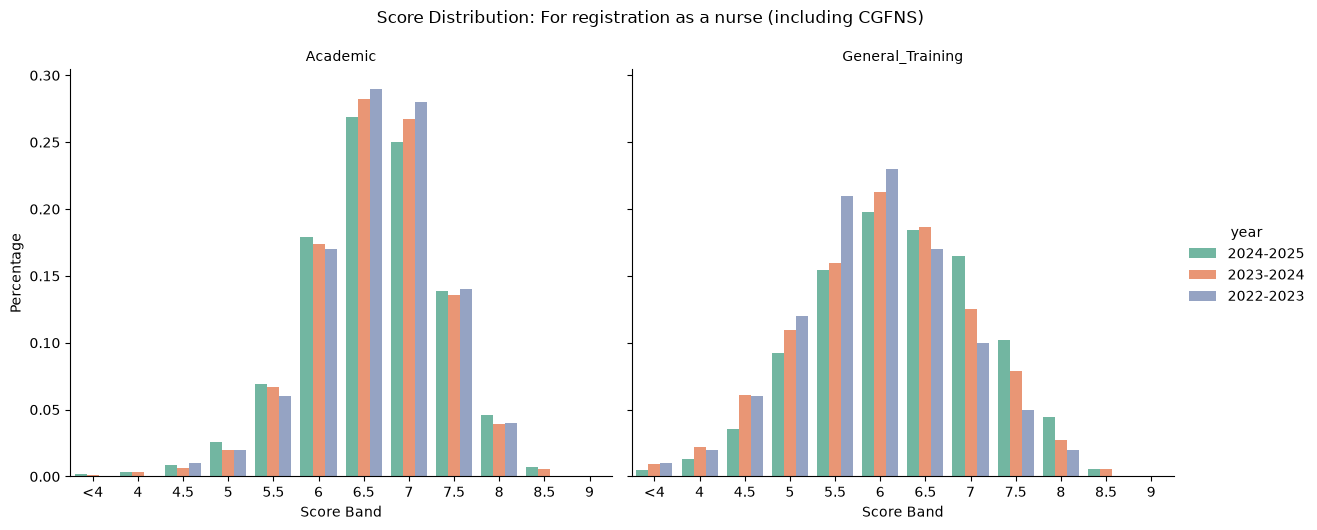

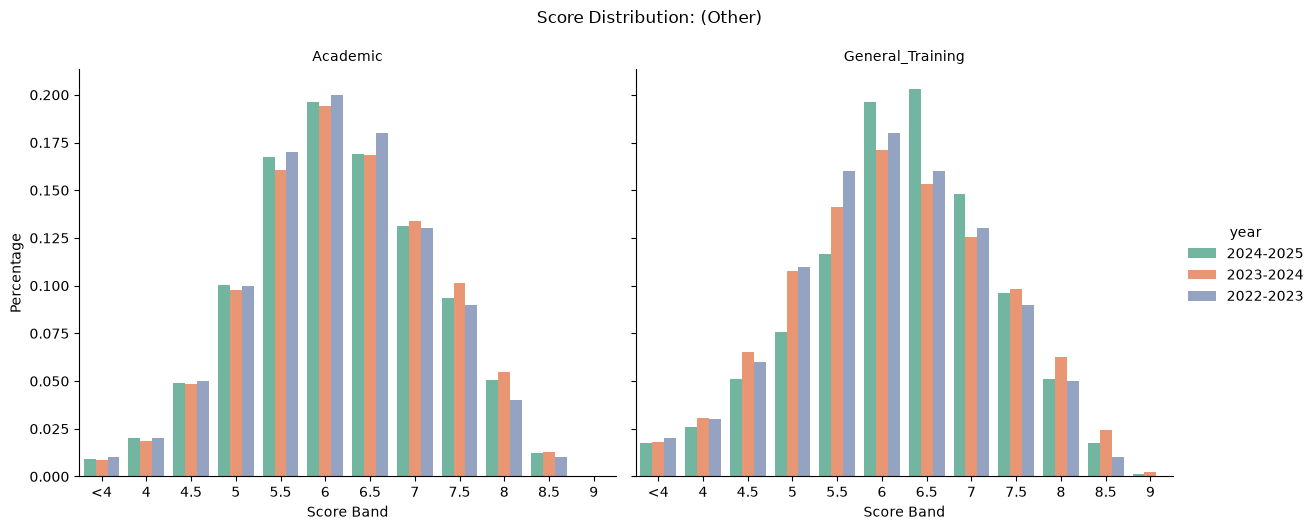

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get unique reasons
reasons = demo_by_reasons["reason"].unique()

# Loop through each reason
for reason in reasons:

    # Filter data for the current reason
    subset = demo_by_reasons[demo_by_reasons["reason"] == reason]

    # Create separate panels for each type
    g = sns.catplot(
        data=subset,
        x="band",
        y="percent",
        hue="year",
        col="type",
        kind="bar",
        height=5,
        aspect=1.2,
        palette="Set2"
    )

    g.set_axis_labels("Score Band", "Percentage")
    g.set_titles("{col_name}")
    g.figure.suptitle(f"Score Distribution: {reason}", y=1.05)

    plt.show()